 # Imports

In [1]:
# -*- coding: utf-8 -*-

import numpy as nmp
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.interpolate import InterpolatedUnivariateSpline as ius
from netCDF4 import Dataset as ncd
import pandas as pd

from specialized_input_data.specialized_input_data import *


 # PHYSICAL PROPERTIES


 ## Global mineral fractions

In [ ]:
"""inp = ncd('emjkok_nomask_variables.nc', 'r')
ymas = (inp.variables['YMAS'][:]).filled() #11 bulk mass %
inp.close()"""
#We take the bulk mass fractions since its the only data we need from that heavy .nc file
ymas = mbulk 

ymas[0] = ymas[0] + ymas[3] + ymas[4] # Illi + Chlo + Verm
ymas[3] = 0.0
ymas[4] = 0.0

print( 'Normalization of ymas: ', nmp.sum(ymas) ) #to check that is =1

#calculate volume %
yvol = ymas/mden #densities (g cm-3)
yvol = yvol/nmp.sum(yvol)
print( 'Normalization of yvol: ', nmp.sum(yvol) )

#m are just the index in the list of minerals
hvol = yvol[mtoh] #host
fvol = yvol[mtof] #IrOx
zvol = yvol[mtoz] #Scanza 2015


Normalization of ymas:  1.0000000706
Normalization of yvol:  1.0


 ## Mineral mass densities

In [3]:
hden = mden[mtoh]
fden = mden[mtof]

dhos = nmp.average(hden, weights=hvol) 
#density of host by a weight avrg of each host mineral density
diox = iden
dhem = fden[0]
dgoe = fden[1]


 ## Scanza refractive indices

In [4]:
zrri, ziri = nmp.zeros([Hz+1,Lx]), nmp.zeros([Hz+1,Lx]) #Hz=7 Scanza host minerals(8)

for m in nmp.arange(Hz+1):

 inp = nmp.loadtxt('./scanza_mineral_data/%s.txt'%(zcri[m]))

 mwvl = inp[:,0]
 nwvl = nmp.where(mwvl[:-1]==mwvl[1:], mwvl[:-1]-1.0e-03, mwvl[:-1])
 mwvl = nmp.append(nwvl, mwvl[-1])

 mrri = inp[:,1]
 miri = inp[:,2]
 miri = nmp.where(miri<0.0, miri*(-1.0), miri)

 SpnLine = ius(mwvl, mrri, k=1, ext=3)
 SpkLine = ius(mwvl, miri, k=1, ext=3)
 zrri[m,:] = SpnLine(xwvl)
 ziri[m,:] = SpkLine(xwvl)

#So ziri (k) and zrri (n) are arrays of 7 rows (one for each scanza mine) (see scanza_mineral_data)
#  and spectral cols. Hematite is the last row

 ### Feldspar refractive index

In [5]:
pick = [0, 1, 2, 3, 4, 6] # Host minerals without feldspar

naux = nmp.average(zrri[pick,:], axis=0, weights=zvol[pick])
kaux = nmp.average(ziri[pick,:], axis=0, weights=zvol[pick])

zrri[5,241:] = naux[241:] # Wavelengths above 2.60um
ziri[5,241:] = kaux[241:]

 ## Host refractive index

In [6]:
nhos = nmp.average(zrri[:-1,:], axis=0, weights=zvol[:-1]) #Hema is the last so doesnt take it
khos = nmp.average(ziri[:-1,:], axis=0, weights=zvol[:-1])
#Same as with host density, the rri is their avrg weighted by their vol %

 ## Iron-oxide refractive indices

 ### Real indices

In [7]:
nhem = zrri[-1,:]
ngoe = nmp.hstack([0.72178*zrri[-1,:Lv], zrri[-1,Lv:]]) # Goethite ~ 0.72178 of hematite at UV-VIS wavelengths (Bedidi and Cervelle)
niox = (nhem + ngoe)/2.0 #just the avrg between them for n

 ### Calculation of khem and kgoe from: keff and mass% of each 18 dust samples (all from DB19)

In [33]:
#Scanza ks is only used for ns and for khost

In [8]:
Q1, Q2, Q3 = nmp.zeros([Lb,2]), nmp.zeros([Lb,2]), nmp.zeros([Lb,2]) #Lb=7 DB19 experimental wvl

#mass %  of each mineral (rows)
M1 = bmas[4,:]*1.0e-02 #Hematite row 
M2 = bmas[5,:]*1.0e-02 #Goethite row
M3 = M1 + M2
MH = 1.0 - M1 - M2 #mass % of Host

# Vol % of each
VH = MH/dhos
V1 = M1/dhem
V2 = M2/dgoe
VT = VH + V1 + V2
V1 = V1/VT
V2 = V2/VT

for l in nmp.arange(Lb):

 def FitBili(vs,q1,q2):
  v1, v2 = vs
  return khos[xtob[l]] + q1*v1 + q2*v2 #xtob are the index of the total specta that match DB19 wvls

 par, var = fit(FitBili, [V1,V2], biri[l,:], sigma=berr[l,:], absolute_sigma=True, bounds=(0.0,+nmp.inf))
 Q1[l,0], Q2[l,0] = par
 Q1[l,1], Q2[l,1] = nmp.sqrt(nmp.diag(var))

V3 = M3/diox
VT = VH + V3
V3 = V3/VT

for l in nmp.arange(Lb):

 def FitLine(v3,q3):
  return khos[xtob[l]] + q3*v3

 par, var = fit(FitLine, V3, biri[l,:], sigma=berr[l,:], absolute_sigma=True, bounds=(0.0,+nmp.inf))
 Q3[l,0] = par[0]
 Q3[l,1] = nmp.sqrt(nmp.diag(var))[0]


 #### Inversion calculation

In [9]:
K1, K2, K3 = nmp.zeros([Lb,3]), nmp.zeros([Lb,3]), nmp.zeros([Lb,3])

KX = nmp.exp(nmp.linspace(nmp.log(0.0001), nmp.log(1.0), 10000))

MP = [0.0, -1.0, 1.0]

for l in nmp.arange(Lb):

 NH = nhos[xtob[l]]
 KH = khos[xtob[l]]
 EH = (NH + 1j*KH)**2

 N1 = nhem[xtob[l]]
 N2 = ngoe[xtob[l]]
 N3 = niox[xtob[l]]
 E1 = (N1 + 1j*KX)**2
 E2 = (N2 + 1j*KX)**2
 E3 = (N3 + 1j*KX)**2

 X1 = (E1 - EH)/(E1 + 2.0*EH)
 X2 = (E2 - EH)/(E2 + 2.0*EH)
 X3 = (E3 - EH)/(E3 + 2.0*EH)
 I1 = (EH*X1).imag
 I2 = (EH*X2).imag
 I3 = (EH*X3).imag
 S1 = (1.5*I1 - KH*(N1 - NH))/NH
 S2 = (1.5*I2 - KH*(N2 - NH))/NH
 S3 = (1.5*I3 - KH*(N3 - NH))/NH

 for s1 in nmp.arange(3):
  h = nmp.argmin(nmp.abs(S1 - (Q1[l,0] + MP[s1]*Q1[l,1])))
  K1[l,s1] = KX[h]

 for s2 in nmp.arange(3):
  g = nmp.argmin(nmp.abs(S2 - (Q2[l,0] + MP[s2]*Q2[l,1])))
  K2[l,s2] = KX[g]

 for s3 in nmp.arange(3):
  i = nmp.argmin(nmp.abs(S3 - (Q3[l,0] + MP[s3]*Q3[l,1])))
  K3[l,s3] = KX[i]


 #### UV-VIS extrapolation

In [10]:
Sp1Line = ius(bwvl, K1[:,0], k=1, ext=3)
Sp2Line = ius(bwvl, K2[:,0], k=1, ext=3)
Sp3Line = ius(bwvl, K3[:,0], k=1, ext=3)

kone = Sp1Line(vwvl)
ktwo = Sp2Line(vwvl)
kthr = Sp3Line(vwvl)


 ### Imaginary indices (result of previous calculations)

In [11]:
khem = nmp.hstack([kone, ziri[-1,Lv:]])

kgoe = nmp.hstack([ktwo, ziri[-1,Lv:]])

kiox = nmp.hstack([kthr, ziri[-1,Lv:]])

In [12]:
"""
So DB19 with Scanzas CRIs calculated CRI for: Host, Hematite, Goethite, Iron Oxides. 
This we will use to calculate SSA in 3 different ways:
 - Homogenous (IMB=0), just use the bulk mass % from "emjkok_nomask_variables.nc". However is the exact same as IMB=2.
 - Varying (IMB=1), Host + IrOx (is a mixure, therefore a common CRI, dens, vol%,...) for 21 (Im) different IrOx mass% (0%->10%).
 - Warying (IMB=2), Host + Hema + Goet for 21 different mass% for each IrOx species (21x21)
"""

'\nSo DB19 with Scanzas CRIs calculated CRI for: Host, Hematite, Goethite, Iron Oxides. \nThis we will use to calculate SSA in 3 different ways:\n - Homogenous (IMB=0), just use the bulk mass % from "emjkok_nomask_variables.nc". However is the exact same as IMB=2.\n - Varying (IMB=1), Host + IrOx (is a mixure, therefore a common CRI, dens, vol%,...) for 21 (Im) different IrOx mass% (0%->10%).\n - Warying (IMB=2), Host + Hema + Goet for 21 different mass% for each IrOx species (21x21)\n'

 ## Playing with the CRI results

 ### Di Biagio wavelengths

In [13]:
out = nmp.column_stack([xwvl[xtob], Q1[:,0], Q2[:,0], Q3[:,0]])
nmp.savetxt('dibiagio_fits.txt', out, fmt='%11.5e') 
#First column are DB19 wvls
out = nmp.column_stack([xwvl[xtob],nhos[xtob],khos[xtob],nhem[xtob],K1[:,0],K1[:,1],K1[:,2],ngoe[xtob],K2[:,0],K2[:,1],K2[:,2],niox[xtob],K3[:,0],K3[:,1],K3[:,2]])
nmp.savetxt('dibiagio_cris.txt', out, fmt='%11.5e') 
#wvl, n and k host, and same for hema, goet, IrOx, but 3 ks for each IrOx for some reason

In [14]:
print(ymas[9], ymas[10])
print(nmp.sum(ymas))

0.005275027 0.01891756
1.0000000706


#### Longtin data implementation

In [15]:
# Introduce Longtin 1988 k dataset and adapt it to our spectral grid
longtin = pd.read_csv(r"C:\Users\Usuario\Desktop\BSC_secondment\hematite_lg88.txt", delim_whitespace=True, header=None, names=["wavelength", "k"])

# Longtin 1988 measured data
longtin_wvl = nmp.array(longtin["wavelength"], dtype=float)
longtin_k = nmp.array(longtin["k"], dtype=float)

# Interpolate onto our spectral grid (XWVL)
XWVL = nmp.linspace(0.200, 12.200, Lx)
khem_longtin = nmp.interp(XWVL, longtin_wvl, longtin_k)

# Linear extrapolation from first measured wavelength down to 300 nm
slope = (longtin_k[1] - longtin_k[0]) / (longtin_wvl[1] - longtin_wvl[0])
mask = XWVL < longtin_wvl[0]
khem_longtin[mask] = longtin_k[0] + slope*(XWVL[mask] - longtin_wvl[0])

# Keep last measured k constant up to 900 nm
khem_longtin[XWVL > longtin_wvl[-1]] = longtin_k[-1]

# Keep original spectral grid (10 nm), up to 900 nm
khem_longtin = khem_longtin[XWVL <= 900]

khem_longtin

C:\Users\Usuario\AppData\Local\Temp\ipykernel_14816\4041299864.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  longtin = pd.read_csv(r"C:\Users\Usuario\Desktop\BSC_secondment\hematite_lg88.txt", delim_whitespace=True, header=None, names=["wavelength", "k"])


array([2.323e+00, 2.233e+00, 2.143e+00, ..., 1.000e-03, 1.000e-03,
       1.000e-03])

#### Exponential empirical approach

In [16]:
def format_decimal(value): #for the names to change the . for a p
    return str(value).replace(".", "p")

In [17]:
# INPUTS
anchor_wavelength = 0.300
anchor_k = 1
anchor_k_decim = int(anchor_k*10)

alpha_values = [3]
n_start, n_end, n_exp = 10, 40, 18 #18 because of python indexation (0 based)

# PREPARATION
XWVL = nmp.array(xwvl)
anchor_idx = nmp.argmin(nmp.abs(XWVL[:n_exp] - anchor_wavelength))

k_values = {"hem": khem, "goe": kgoe, "iox": kiox}
k_modified = {}

# CALCULATIONS
for name, k in k_values.items():
    k = nmp.array(k, dtype=float)

    for alpha in alpha_values:
        k_new = k.copy()
        D = anchor_k - k[anchor_idx]

        x = (XWVL[n_exp-1] - XWVL[:n_exp]) / (XWVL[n_exp-1] - XWVL[anchor_idx])
        shape = nmp.expm1(alpha*x) / nmp.expm1(alpha)

        k_new[:n_exp] = k[:n_exp] + D*shape
        k_new[anchor_idx] = anchor_k

        alpha_str = format_decimal(alpha)
        key = f"k{name}_{anchor_k_decim}exp_{alpha_str}"
        k_modified[key] = k_new
        globals()[key] = k_new


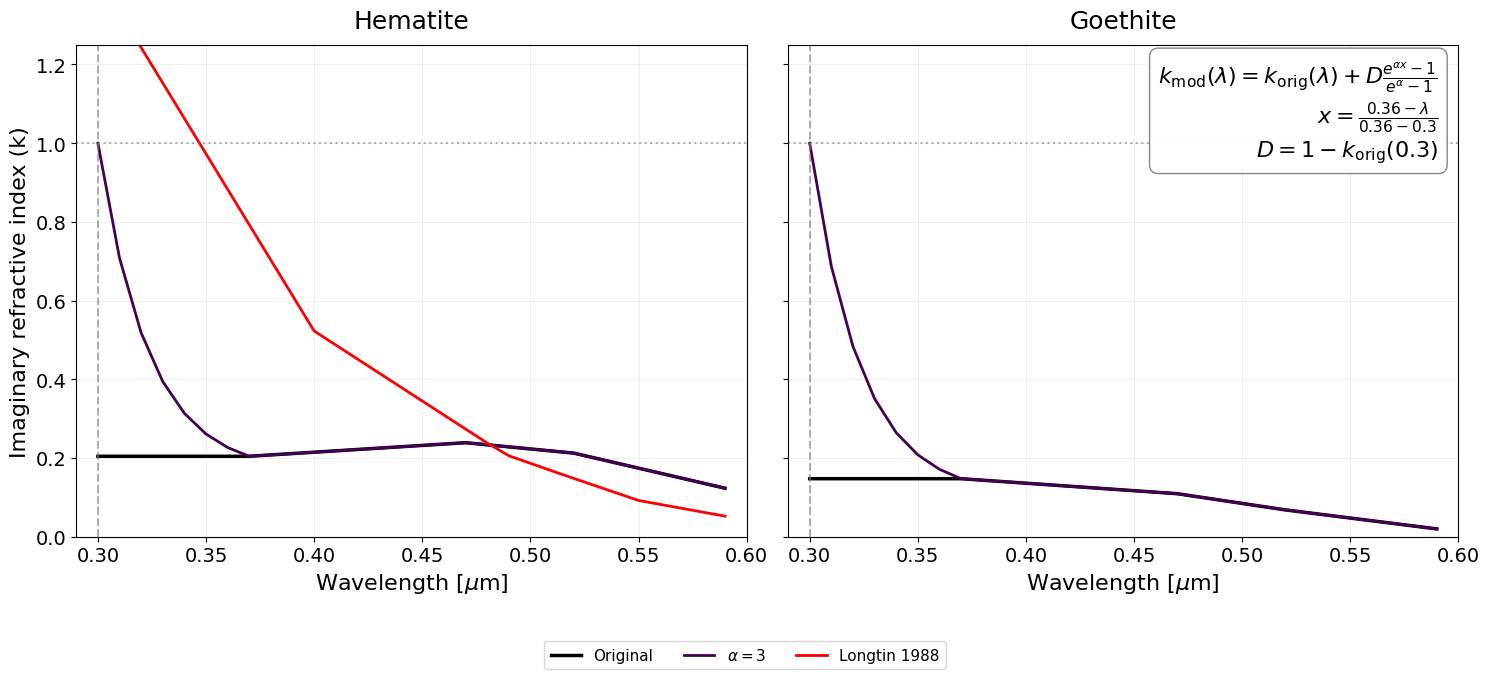

In [18]:

# PLOTTING
colors = plt.cm.viridis(nmp.linspace(0, 1, len(alpha_values)))
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

for ax, name, title in zip(axes, ["hem", "goe"], ["Hematite", "Goethite"]):
    ax.plot(XWVL[n_start:n_end], k_values[name][n_start:n_end],
            color="black", linewidth=2.5, label="Original")

    for j, alpha in enumerate(alpha_values):
        alpha_str = format_decimal(alpha)
        key = f"k{name}_{anchor_k_decim}exp_{alpha_str}"
        ax.plot(XWVL[n_start:n_end], k_modified[key][n_start:n_end],
                color=colors[j], linewidth=2, label=rf"$\alpha={alpha}$")

    if name == "hem":
        ax.plot(XWVL[n_start:n_end], khem_longtin[n_start:n_end],
                color="red", linewidth=2, label="Longtin 1988")

    ax.axvline(anchor_wavelength, color="grey", linestyle="--", alpha=0.6)
    ax.axhline(anchor_k, color="grey", linestyle=":", alpha=0.6)
    ax.set_title(title, fontsize=18, pad=12)
    ax.set_xlabel(r"Wavelength [$\mu$m]", fontsize=16)
    ax.set_ylim(0.00, 1.25)
    ax.set_xlim(XWVL[n_start]-0.01, XWVL[n_end-1]+0.01)
    ax.tick_params(axis="both", labelsize=14)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Imaginary refractive index (k)", fontsize=16)

equation = (
    r"$k_{\mathrm{mod}}(\lambda)=k_{\mathrm{orig}}(\lambda)"
    r"+D\frac{e^{\alpha x}-1}{e^\alpha-1}$" "\n"
    r"$x=\frac{0.36-\lambda}{0.36-0.3}$" "\n"
    r"$D=1-k_{\mathrm{orig}}(0.3)$"
)

axes[1].text(0.97, 0.97, equation, transform=axes[1].transAxes,
             ha="right", va="top", fontsize=16,
             bbox=dict(facecolor="white", alpha=0.95,
                       edgecolor="grey", boxstyle="round,pad=0.4"))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center",
           bbox_to_anchor=(0.5, 0.025),
           ncol=min(5, len(labels)), fontsize=11, frameon=True)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()


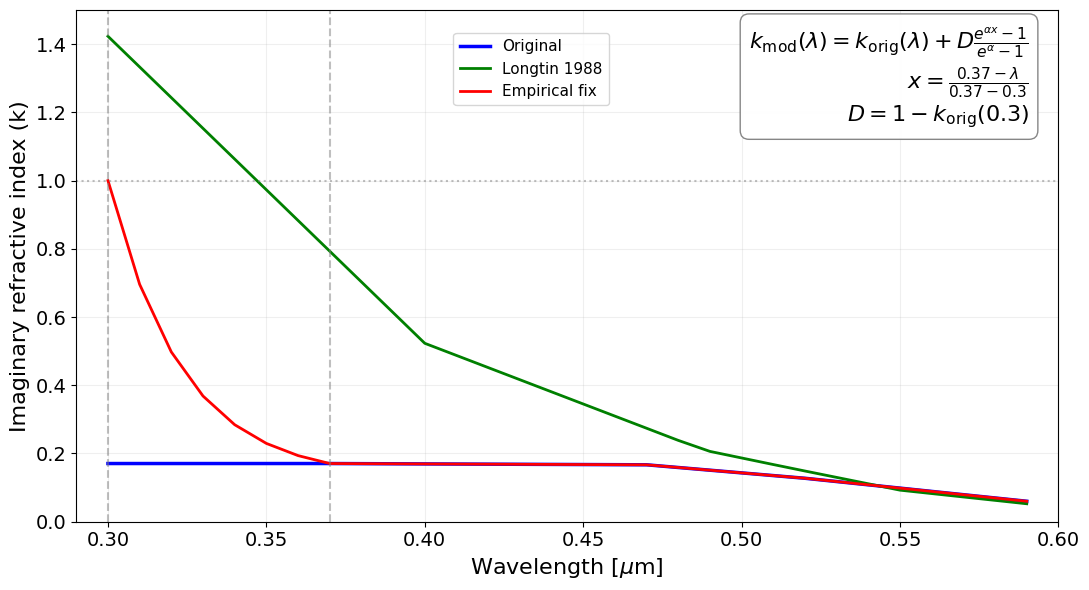

In [19]:
# PLOTTING
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(XWVL[n_start:n_end], kiox[n_start:n_end],
        color="blue", linewidth=2.5, label="Original")

ax.plot(XWVL[n_start:n_end], khem_longtin[n_start:n_end],
        color="green", linewidth=2, label="Longtin 1988")

alpha_str = format_decimal(alpha_values[0])
key = f"kiox_{anchor_k_decim}exp_{alpha_str}"

ax.plot(XWVL[n_start:n_end], k_modified[key][n_start:n_end],
        color="red", linewidth=2, label="Empirical fix")

#ax.axes.set_yscale('log')
ax.axvline(0.300, color="grey", linestyle="--", alpha=0.5)
ax.axvline(0.370, color="grey", linestyle="--", alpha=0.5)
ax.axhline(anchor_k, color="grey", linestyle=":", alpha=0.5)
ax.set_xlabel(r"Wavelength [$\mu$m]", fontsize=16)
ax.set_ylabel("Imaginary refractive index (k)", fontsize=16)
ax.set_ylim(0.00, 1.5)
ax.set_xlim(XWVL[n_start]-0.01, XWVL[n_end-1]+0.01)
ax.tick_params(axis="both", labelsize=14)
ax.grid(alpha=0.2)

equation = (
    r"$k_{\mathrm{mod}}(\lambda)=k_{\mathrm{orig}}(\lambda)"
    r"+D\frac{e^{\alpha x}-1}{e^\alpha-1}$" "\n"
    r"$x=\frac{0.37-\lambda}{0.37-0.3}$" "\n"
    r"$D=1-k_{\mathrm{orig}}(0.3)$"
)

ax.text(0.97, 0.97, equation, transform=ax.transAxes, ha="right", va="top", fontsize=16,
        bbox=dict(facecolor="white", alpha=0.95, edgecolor="grey", boxstyle="round,pad=0.4"))
ax.legend(loc="upper right", bbox_to_anchor=(0.55, 0.97), fontsize=11, frameon=True)

plt.tight_layout()
plt.show()

In [20]:
khem = khem_10exp_3
kgoe = kgoe_10exp_3
kiox = kiox_10exp_3

In [21]:
Mie_LUT_name = "mineral_monochromatic_table_empirical_moreWL"  #(_empirical_fix is the same as _10exp_3)

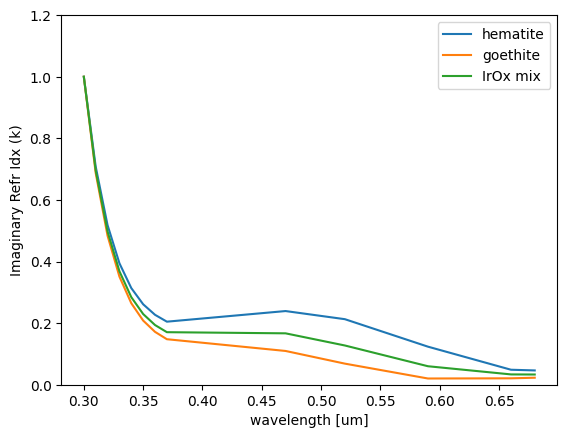

In [22]:
n = 49 # the wvls index in xwvl for the last visible wvl: 780nm
plt.plot(xwvl[10:n], khem[10:n], label="hematite")
plt.plot(xwvl[10:n], kgoe[10:n], label="goethite")
plt.plot(xwvl[10:n], kiox[10:n], label="IrOx mix")
plt.ylim([0,1.2])
plt.xlabel("wavelength [um]")
plt.ylabel("Imaginary Refr Idx (k)")
plt.legend()

 # OPTICAL PROPERTIES

In [23]:
qext, qsca, qasy = nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]) #For IMB=0
vext, vsca, vasy = nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]) #For IMB=1
wext, wsca, wasy = nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]) #For IMB=2
#Altough only IMB=2 will fill all the dimensions (21 bins of 2 IrOx species) all need to have same shape for the netCDF file.

 ## Homogeneous dust physics

In [ ]:
vhos = nmp.sum(hvol)
vhem = fvol[0]
vgoe = fvol[1]
#Check the vol % of host+hema+goe is 1
print('vhem:',vhem,' , vgoe:',vgoe)
print( 'vhos + vhem + vgoe: ', vhos+vhem+vgoe )

ddus = dhos*vhos + dhem*vhem + dgoe*vgoe 
#(density of the homogenous mixture by a weight avrg) (weight = vol%)
#Maxwell-Garnett (permitivities and so on):
ehos = (nhos + 1j*khos)**2 #e==permitivity (=CRI^2) (needed for mixing rule)
ehem = (nhem + 1j*khem)**2
egoe = (ngoe + 1j*kgoe)**2

xhem = (ehem - ehos)/(ehem + 2.0*ehos)
xgoe = (egoe - ehos)/(egoe + 2.0*ehos)

ymxg = xhem*vhem + xgoe*vgoe 
emxg = ehos*(1.0 + 2.0*ymxg)/(1.0 - ymxg) 

#Once you have the effective permitivity, back to CRI with the sqrt:
ndus = nmp.sqrt(emxg).real
kdus = nmp.sqrt(emxg).imag
#They are spectral values for each of Scanzas wvl (1200) (Lx)

vhem: 0.0026649265871168254  , vgoe: 0.012003522323463295
vhos + vhem + vgoe:  1.0


 ### Shortwave wavelengths


In [25]:
#All the CRI values for the 1200 wvls
out = nmp.column_stack([xwvl, nhos, khos, nhem, khem, ngoe, kgoe, niox, kiox, ndus, kdus])
nmp.savetxt('shortwave_cris.txt', out, fmt='%11.5e')

 ## Mixture refractive index

In [ ]:
def MixCris(INB):
 """
   Retrurns the k and n of dust for different mixtures types using Maxwell-Garnett.

   Varying ING (the input) you select the type of mixure you want:
   IMB=0: Same as IMB=2 but for fixed mass% of hema and goet (from emjkok) (dim:(1200))
   IMB=1: Host + IrOx (dim:(21,0,1200)) (only 1 IrOx specie)
   IMB=2: Host + Hematite + Goethite (dim:(21,21,1200))(2 IrOx species)
 """

 NMX, KMX = nmp.zeros([Im,Im,Lx]), nmp.zeros([Im,Im,Lx])  #Im=21 Grid IrOx mass-fractions (see M3), Lx=1200 wvls

 if INB == 0:
  NMX[:,:,:] = ndus #Takes the previous calculated n and k for the mix (emjkok_nomask)
  KMX[:,:,:] = kdus #Linear arrays of Lx elements (but repeated in the 2 first dims (Im,Im) for consistency with other IMB)
################################################################

 if INB == 1:
  for m3 in nmp.arange(Im):

   M3 = igrd[m3] #just the grid for different cases of IrOx % (0% to 10%, Im(20) steps)
   MH = 1.0 - M3 #the rest is host (therefore from 100% to 90%)

   VH = MH/dhos #vol % with the respect densities
   V3 = M3/diox
   VT = VH + V3
   VH = VH/VT
   V3 = V3/VT

#Again Maxwell-Garnett mixing rule with permitivities (E=CRI^2)
   EHS = (nhos + 1j*khos)**2
   EIX = (niox + 1j*kiox)**2

   XIX = (EIX - EHS)/(EIX + 2.0*EHS)

   YMX = XIX*V3
   EMX = EHS*(1.0 + 2.0*YMX)/(1.0 - YMX)

#Result for IMB=1 (first dim is just the index (0,20)) (but each represents a IrOx mass % (see M3))
   NMX[m3,:,:] = nmp.sqrt(EMX).real
   KMX[m3,:,:] = nmp.sqrt(EMX).imag
################################################################

 if INB == 2:
  for m1 in nmp.arange(Im):
   for m2 in nmp.arange(Im):

    M1 = igrd[m1] #Same but now both hema and goet cases (0% to 10%, Im(20) steps)
    M2 = igrd[m2] #Thats why now we need the 3 dim array (21,21,1200)
    MH = 1.0 - M1 - M2

    VH = MH/dhos #Same as before: vol %
    V1 = M1/dhem
    V2 = M2/dgoe
    VT = VH + V1 + V2
    VH = VH/VT
    V1 = V1/VT
    V2 = V2/VT

#Max-Garn multicomponent with a common host (small mod, see notes)
    EHS = (nhos + 1j*khos)**2
    EHM = (nhem + 1j*khem)**2
    EGT = (ngoe + 1j*kgoe)**2

    XHM = (EHM - EHS)/(EHM + 2.0*EHS)
    XGT = (EGT - EHS)/(EGT + 2.0*EHS)

    YMX = XHM*V1 + XGT*V2
    EMX = EHS*(1.0 + 2.0*YMX)/(1.0 - YMX)

#Result for IMB=2 (first and sec dim are just the index (0,20)) (but each represents a hema/goet mass % (see M1,M2))
    NMX[m1,m2,:] = nmp.sqrt(EMX).real
    KMX[m1,m2,:] = nmp.sqrt(EMX).imag

 return NMX, KMX

 ## Monodisperse Mie parameters

In [27]:
"""
Interpolates the Mie parameters (Qext, Qsca, g) (extinction efficiency, scattering efficiency, and asymmetry parameter) 
 for a given comp refractive index (RRI and IRI)
 (Because for spherical particles, Mie efficiencies depend on the size parameter x, and the complex refractive index).
The function uses bilinear interpolation on the precomputed Mie parameters stored in the 3D LUT (monodisperse_mie_parameters.nc).
Basically retrieves from the Mie LUTs the 3 Mie properties for given RRI and IRI, but those 3 are arrays since they are still function of X (size parameter).

(Nothing to change in any of these mie files/functions)
"""

inp = ncd('monodisperse_mie_parameters.nc', 'r')
xext = (inp.variables['XEXT'][:,:,:]).filled() # [N,K,X]
xsca = (inp.variables['XSCA'][:,:,:]).filled()
xasy = (inp.variables['XASY'][:,:,:]).filled()
inp.close()

def MieMono(RRI,IRI):

 RRI = min(max(RRI, ngrd[0]), ngrd[-1])
 IRI = min(max(IRI, kgrd[0]), kgrd[-1])

 for n in nmp.arange(N-1):
  YEN = (ngrd[n] - RRI)*(ngrd[n+1] - RRI)
  if YEN <= 0.0:
   n1 = n
   n2 = n + 1
   NG1 = ngrd[n]
   NG2 = ngrd[n+1]
 for k in nmp.arange(K-1):
  YEK = (kgrd[k] - IRI)*(kgrd[k+1] - IRI)
  if YEK <= 0.0:
   k1 = k
   k2 = k + 1
   KG1 = kgrd[k]
   KG2 = kgrd[k+1]

 DNK = (NG2 - NG1)*(KG2 - KG1)
 W11 = (NG2 - RRI)*(KG2 - IRI)/DNK
 W12 = (NG2 - RRI)*(IRI - KG1)/DNK
 W21 = (RRI - NG1)*(KG2 - IRI)/DNK
 W22 = (RRI - NG1)*(IRI - KG1)/DNK

 W11 = min(max(W11, 0.0), 1.0)
 W12 = min(max(W12, 0.0), 1.0)
 W21 = min(max(W21, 0.0), 1.0)
 W22 = min(max(W22, 0.0), 1.0)

 QEX = xext[n1,k1,:]*W11 + xext[n1,k2,:]*W12 + xext[n2,k1,:]*W21 + xext[n2,k2,:]*W22
 QSX = xsca[n1,k1,:]*W11 + xsca[n1,k2,:]*W12 + xsca[n2,k1,:]*W21 + xsca[n2,k2,:]*W22
 QGX = xasy[n1,k1,:]*W11 + xasy[n1,k2,:]*W12 + xasy[n2,k1,:]*W21 + xasy[n2,k2,:]*W22

 return QEX, QSX, QGX


 ## Size bin integration (MONARCH 8)

In [28]:
def IntSize(QEX,QSX,QGX,WVL):

 """
Takes the Mie properties for individual particle sizes and calculates size-averaged optical properties for a particle size distribution.
Inputs: Ext and Scatt efficiencies, asym and wvl (Mie properties + wvl).

Here is where you go from wavelengths to Mie properties. You require a wvl in te input (WVL) 

Difference from MieMono:
MieMono gives you optical (Mie) properties for each individual particle size (for a default wvl of 550nm),
 however, Mie properties depend on the size parameter x=2pi*r/wvl, unitless and can get the same value for different combinations of r and wvl.
 IntSize combines those individual-size results into averages for a series of particle size bins, 
 accounting for how many particles of each size are present and how efficiently they interact with light.
 The function returns four arrays of length S (Dust size bins (Dustcomm)):
 Size-averaged ext and scatt efficiencies, scattering weighted asymm and Cross-sectional-area-weighted mean particle radius in each bin

 (Nothing to change in any of these mie files/functions)
 """

 QES, QSS, QGS = nmp.zeros(S), nmp.zeros(S), nmp.zeros(S)

 RFF = nmp.zeros(S)

 for s in nmp.arange(S):

  SA = sbin[s]
  SB = sbax[s]

  RAD = xgrd*WVL/(2.0*nmp.pi)
  PRR = nmp.pi*RAD**2

  RG = rgeo
  SG = sgeo
  LGN = LogNorm(RAD,RG,SG)

  AB = (SA <= RAD)*(RAD <= SB)

  QES[s] = nmp.trapz(        QEX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(        PRR[AB]*LGN[AB], x=RAD[AB])
  QSS[s] = nmp.trapz(        QSX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(        PRR[AB]*LGN[AB], x=RAD[AB])
  QGS[s] = nmp.trapz(QGX[AB]*QSX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(QSX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])

  RFF[s] = nmp.trapz(        RAD[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(        PRR[AB]*LGN[AB], x=RAD[AB])

 return QES, QSS, QGS, RFF

 ## Spectral band averaging

### Monochrmatic instead of Spectral BANDS

In [29]:
def wvl_selection(QEL, QSL, QGL, wavelengths):

    """
    Selects the Mie parameters (ext and scat efficiencies, and g) for specific wavelengths from the full spectral data.
    This selects the nearest wavelength-grid point to each requested wavelength instead of averaging as in AvgBand.
    Same inputs but adding a list (of floats) of selected wvls (in um)
    """

    QEM, QSM, QGM = [], [], [] #M for Monochromatic instead of B for Band-averaged

    for wvl in wavelengths:
        idx = nmp.argmin(nmp.abs(xwvl - wvl))
        QEM.append(QEL[:, idx])
        QSM.append(QSL[:, idx])
        QGM.append(QGL[:, idx])

    return nmp.stack(QEM, axis=1), \
           nmp.stack(QSM, axis=1), \
           nmp.stack(QGM, axis=1)

 ## Grid optical properties

In [30]:
for INB in [0, 1]: #, 2

 NMX, KMX = MixCris(INB) # [Im,Im,Lx]

 print( 'INB: ', INB, 'min(NMX): ', nmp.amin(NMX), 'max(NMX): ', nmp.amax(NMX), 'min(KMX): ', nmp.amin(KMX), 'max(KMX): ', nmp.amax(KMX) )

 Im1 = int(INB==0) + int(INB==1)*Im + int(INB==2)*Im
 Im2 = int(INB==0) + int(INB==1) + int(INB==2)*Im
 #Gives the corresponding number of iterations for each INB case (0,1,2) (0:1,1 - 1:21,1 - 2:21x21)
 print( 'Im1: ', Im1, 'Im2: ', Im2 )

 for m1 in nmp.arange(Im1):
  for m2 in nmp.arange(Im2):

   print( 'm1: ', m1, 'm2: ', m2 )

   QEL, QSL, QGL = nmp.zeros([S,Lx]), nmp.zeros([S,Lx]), nmp.zeros([S,Lx])

   if INB == 0: REL = nmp.zeros([S,Lx])

   for l in nmp.arange(Lx):

    RRI = NMX[m1,m2,l]
    IRI = KMX[m1,m2,l]

    QEX, QSX, QGX = MieMono(RRI,IRI) # [X]

    WVL = xwvl[l]  #Runs Int Size for each wavelength (Lx=1200) 

    QES, QSS, QGS, RFF = IntSize(QEX,QSX,QGX,WVL) # [S]

    QEL[:,l] = QES
    QSL[:,l] = QSS
    QGL[:,l] = QGS

    if INB == 0: REL[:,l] = RFF

   QEM, QSM, QGM = wvl_selection(QEL, QSL, QGL, wvl_micron)
   print(QEM)

   if INB == 0:
    dens = nmp.ones(S)*ddus
    reff = nmp.mean(REL, axis=1) # [S]
    qext[:,:,m1,m2] = QEM 
    qsca[:,:,m1,m2] = QSM
    qasy[:,:,m1,m2] = QGM

   if INB == 1:
    vext[:,:,m1,m2] = QEM
    vsca[:,:,m1,m2] = QSM
    vasy[:,:,m1,m2] = QGM

   if INB == 2:
    wext[:,:,m1,m2] = QEM
    wsca[:,:,m1,m2] = QSM
    wasy[:,:,m1,m2] = QGM

INB:  0 min(NMX):  0.5763102535577247 max(NMX):  2.3967798877991013 min(KMX):  0.0006075893257956119 max(KMX):  2.3375834505333835
Im1:  1 Im2:  1
m1:  0 m2:  0


C:\Users\Usuario\AppData\Local\Temp\ipykernel_14816\625300831.py:38: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  QES[s] = nmp.trapz(        QEX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(        PRR[AB]*LGN[AB], x=RAD[AB])
C:\Users\Usuario\AppData\Local\Temp\ipykernel_14816\625300831.py:39: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  QSS[s] = nmp.trapz(        QSX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(        PRR[AB]*LGN[AB], x=RAD[AB])
C:\Users\Usuario\AppData\Local\Temp\ipykernel_14816\625300831.py:40: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  QGS[s] = nmp.trapz(QGX[AB]*QSX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])/nmp.trapz(QSX[AB]*PRR[AB]*LGN[AB], x=RAD[AB])
C:\Users\Usuario\AppData\Local\Temp\ipykernel_14816\

[[3.23053829 3.08750606 2.99562362 2.86919356 2.78296092 1.97987944
  0.60548435 0.29453825]
 [3.67677806 3.78979275 3.86756839 3.94949757 3.97946744 3.84205306
  2.17507263 1.32528055]
 [2.40580748 2.4054817  2.38525047 2.38281542 2.37929293 2.65048593
  3.8505456  3.4968787 ]
 [2.30626838 2.3287365  2.36291178 2.38282984 2.39779781 2.50952079
  2.27133855 3.19225555]
 [2.2116809  2.20633912 2.2138158  2.22839758 2.25466941 2.29992894
  2.49823692 2.34489695]
 [2.16544428 2.1742971  2.17046555 2.16206335 2.15905832 2.18157566
  2.30452419 2.21971414]
 [2.11444898 2.11250852 2.11416542 2.12061612 2.12343913 2.13336146
  2.21778444 2.25845377]
 [2.07341942 2.07544841 2.0766218  2.07821775 2.08009213 2.09129065
  2.10835827 2.13184514]]
INB:  1 min(NMX):  0.5490104160406384 max(NMX):  2.40042339677415 min(KMX):  0.00029687789274768006 max(KMX):  2.394330972164453
Im1:  21 Im2:  1
m1:  0 m2:  0
[[3.23785073 3.08021248 2.98743935 2.86046722 2.77334803 1.91352208
  0.5843713  0.27607935]
 [

 ## Mineral shortwave table

In [31]:
igrd = nmp.linspace(0.00, 0.10, Im) #(step=0.005)
#Taken from specialized_input_data.py

In [32]:
out = ncd(f'Mie_IrOx_LUT/{Mie_LUT_name}.nc', 'w', format='NETCDF4')
out.createDimension('S', S)
out.createDimension('B_mono', B_mono)
out.createDimension('Im', Im)

# --- --- ---
WVL = out.createVariable('WVL', 'f4', ('B_mono',))
WVL.units = 'um'
WVL.long_name = 'Selected monochromatic wavelengths'
WVL[:] = wvl_micron
# --- --- ---
FeOx = out.createVariable('FeOx', 'f4', ('Im',))
FeOx.units = '%'
FeOx.long_name = 'Iron oxide mass percentage'
FeOx[:] = igrd
# --- --- ---
DENS = out.createVariable('DENS', 'f4', ('S',))
DENS.units = 'g cm-3'
DENS.long_name = 'Dust mass density'
# --- --- ---
REFF = out.createVariable('REFF', 'f4', ('S',))
REFF.units = 'um'
REFF.long_name = 'Dust effective radius'
# --- --- ---
QEXT = out.createVariable('QEXT', 'f4', ('S','B_mono'))
QEXT.units = '-'
QEXT.long_name = 'Homogeneous extinction efficiency'
# --- --- ---
QSCA = out.createVariable('QSCA', 'f4', ('S','B_mono'))
QSCA.units = '-'
QSCA.long_name = 'Homogeneous scattering efficiency'
# --- --- ---
QASY = out.createVariable('QASY', 'f4', ('S','B_mono'))
QASY.units = '-'
QASY.long_name = 'Homogeneous asymmetry parameter'
# --- --- ---
VEXT = out.createVariable('VEXT', 'f4', ('S','B_mono','Im'))
VEXT.units = '-'
VEXT.long_name = 'Varying extinction efficiency'
# --- --- ---
VSCA = out.createVariable('VSCA', 'f4', ('S','B_mono','Im'))
VSCA.units = '-'
VSCA.long_name = 'Varying scattering efficiency'
# --- --- ---
VASY = out.createVariable('VASY', 'f4', ('S','B_mono','Im'))
VASY.units = '-'
VASY.long_name = 'Varying asymmetry parameter'
"""# --- --- ---
WEXT = out.createVariable('WEXT', 'f4', ('S','B_mono','Im','Im'))
WEXT.units = '-'
WEXT.long_name = 'Warying extinction efficiency'
# --- --- ---
WSCA = out.createVariable('WSCA', 'f4', ('S','B_mono','Im','Im'))
WSCA.units = '-'
WSCA.long_name = 'Warying scattering efficiency'
# --- --- ---
WASY = out.createVariable('WASY', 'f4', ('S','B_mono','Im','Im'))
WASY.units = '-'
WASY.long_name = 'Warying asymmetry parameter'
# --- --- ---"""
DENS[:] = dens
REFF[:] = reff
QEXT[:,:] = qext[:,:,0,0]
QSCA[:,:] = qsca[:,:,0,0]
QASY[:,:] = qasy[:,:,0,0]
VEXT[:,:,:] = vext[:,:,:,0]
VSCA[:,:,:] = vsca[:,:,:,0]
VASY[:,:,:] = vasy[:,:,:,0]
"""WEXT[:,:,:,:] = wext
WSCA[:,:,:,:] = wsca
WASY[:,:,:,:] = wasy"""
out.close()


 # End of script